In [1]:
!pip install scikit-learn==1.9.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 53.0 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.6.1
    Uninstalling scikit-learn-1.6.1:
      Successfully uninstalled scikit-learn-1.6.1


## Project : Credit Card Default Risk Prediction System

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Loading

In [3]:
df = pd.read_csv("/content/Credit Card Defaulter Prediction.csv")
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,1,20000,F,University,Married,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,Y
1,2,120000,F,University,Single,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,Y
2,3,90000,F,University,Single,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,N
3,4,50000,F,University,Married,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,N
4,5,50000,M,University,Married,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,N


In [4]:
df.tail()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
29995,29996,220000,M,High School,Married,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,N
29996,29997,150000,M,High School,Single,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,N
29997,29998,30000,M,University,Single,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,Y
29998,29999,80000,M,High School,Married,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,Y
29999,30000,50000,M,University,Married,46,0,0,0,0,...,36535,32428,15313,2078,1800,1430,1000,1000,1000,Y


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         30000 non-null  int64 
 1   LIMIT_BAL  30000 non-null  int64 
 2   SEX        30000 non-null  object
 3   EDUCATION  30000 non-null  object
 4   MARRIAGE   30000 non-null  object
 5   AGE        30000 non-null  int64 
 6   PAY_0      30000 non-null  int64 
 7   PAY_2      30000 non-null  int64 
 8   PAY_3      30000 non-null  int64 
 9   PAY_4      30000 non-null  int64 
 10  PAY_5      30000 non-null  int64 
 11  PAY_6      30000 non-null  int64 
 12  BILL_AMT1  30000 non-null  int64 
 13  BILL_AMT2  30000 non-null  int64 
 14  BILL_AMT3  30000 non-null  int64 
 15  BILL_AMT4  30000 non-null  int64 
 16  BILL_AMT5  30000 non-null  int64 
 17  BILL_AMT6  30000 non-null  int64 
 18  PAY_AMT1   30000 non-null  int64 
 19  PAY_AMT2   30000 non-null  int64 
 20  PAY_AMT3   30000 non-null  i

In [6]:
df.describe()

,ID,LIMIT_BAL,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,3.000000e+04,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,-0.291100,51223.330900,...,4.701315e+04,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567
std,8660.398374,129747.661567,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,1.149988,73635.860576,...,6.934939e+04,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775
min,1.000000,10000.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,-165580.000000,...,-1.572640e+05,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,3558.750000,...,2.666250e+03,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000
50%,15000.500000,140000.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,22381.500000,...,2.008850e+04,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000
75%,22500.250000,240000.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67091.000000,...,6.016475e+04,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000
max,30000.000000,1000000.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,8.000000,964511.000000,...,1.664089e+06,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000


In [7]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default '],
      dtype='object')

In [8]:
df.rename(columns={'default ': 'default'}, inplace=True)

In [9]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default'],
      dtype='object')

## Data Cleaning

In [10]:
df.isnull().sum()

,0
ID,0
LIMIT_BAL,0
SEX,0
EDUCATION,0
MARRIAGE,0
AGE,0
PAY_0,0
PAY_2,0
PAY_3,0
PAY_4,0


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.shape

(30000, 25)

In [13]:
df.size

750000

In [14]:
df.dtypes

,0
ID,int64
LIMIT_BAL,int64
SEX,object
EDUCATION,object
MARRIAGE,object
AGE,int64
PAY_0,int64
PAY_2,int64
PAY_3,int64
PAY_4,int64


In [15]:
df.nunique()

,0
ID,30000
LIMIT_BAL,81
SEX,2
EDUCATION,6
MARRIAGE,4
AGE,56
PAY_0,11
PAY_2,11
PAY_3,11
PAY_4,11


In [16]:
print(df['SEX'].unique())
print(df['EDUCATION'].unique())
print(df['MARRIAGE'].unique())

['F' 'M']
['University' 'Graduate school' 'High School' 'Unknown' 'Others' '0']
['Married' 'Single' 'Other' '0']


In [17]:
df['default'].value_counts()

,count
default,
N,23364
Y,6636


In [18]:
df['default'].value_counts(normalize=True) * 100

,proportion
default,
N,77.88
Y,22.12


In [19]:
df['EDUCATION'] = df['EDUCATION'].replace('0', 'Others')

In [20]:
df['EDUCATION'].value_counts()

,count
EDUCATION,
University,14030
Graduate school,10585
High School,4917
Unknown,331
Others,137


In [21]:
df['MARRIAGE'] = df['MARRIAGE'].replace('0', 'Other')
df['MARRIAGE'].value_counts()

,count
MARRIAGE,
Single,15964
Married,13659
Other,377


## Exploratory Data Analysis

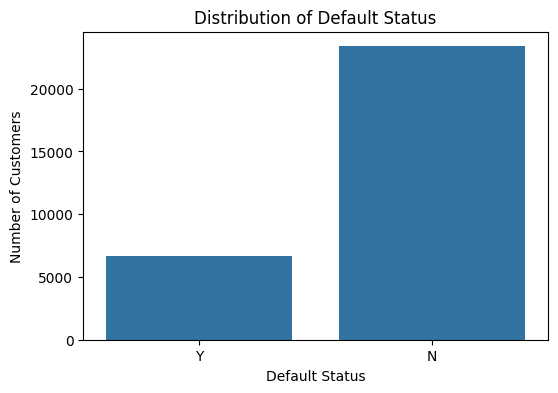

In [22]:
# Default distribution
plt.figure(figsize=(6,4))
ax = sns.countplot(data=df, x='default')
plt.title('Distribution of Default Status')
plt.xlabel('Default Status')
plt.ylabel('Number of Customers')
plt.show()

- There are more number of customers who may not default next month.

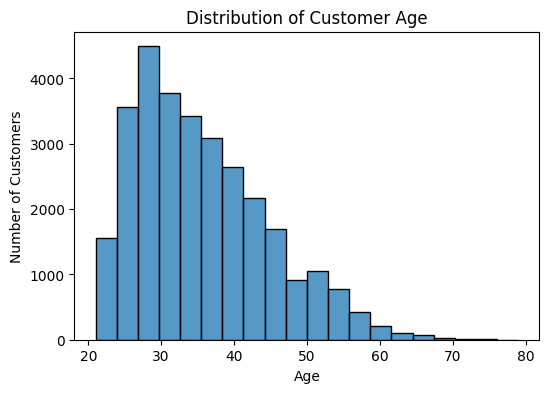

In [23]:
# Age distribution
plt.figure(figsize=(6,4))
sns.histplot(data=df, x='AGE', bins=20)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

- The customer age distribution is right-skewed, with the vast majority of customers concentrated in the 25 to 40 age range. As age increases beyond 40, the number of customers steadily declines, showing very few customers aged 60 and above.

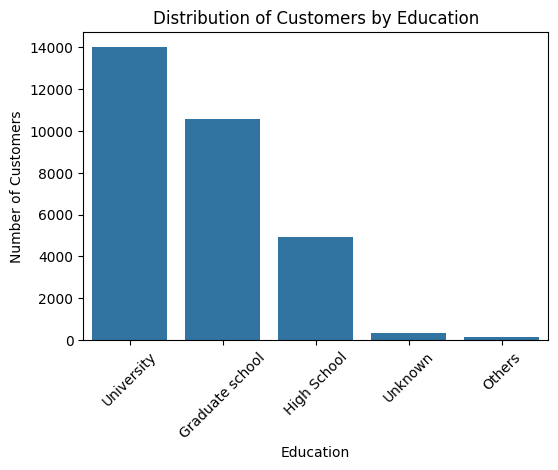

In [24]:
# Education disribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='EDUCATION')
plt.title('Distribution of Customers by Education')
plt.xlabel('Education')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.show()

- Most customers have university education or graduate school education, followed by high school. Very few customers fall under unknown and others.

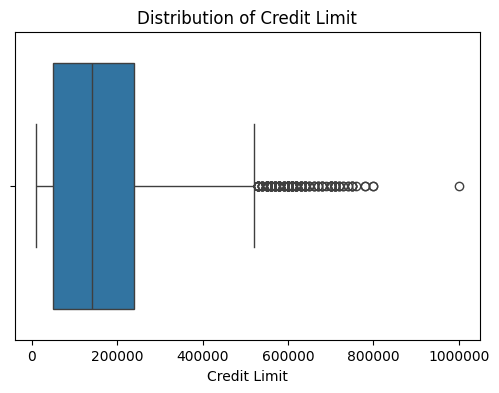

In [25]:
# Credit limit distribution
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='LIMIT_BAL')
plt.title('Distribution of Credit Limit')
plt.xlabel('Credit Limit')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

- Most customers have a relatively lower credit limit, with the middle 50% (50% from box).
- The distribution is heavily right skewed, meaning smaller credit limits are far more common than higher limits.
- There are several high value outliers on right side of the graph, representing a small group of high credit premium costs.

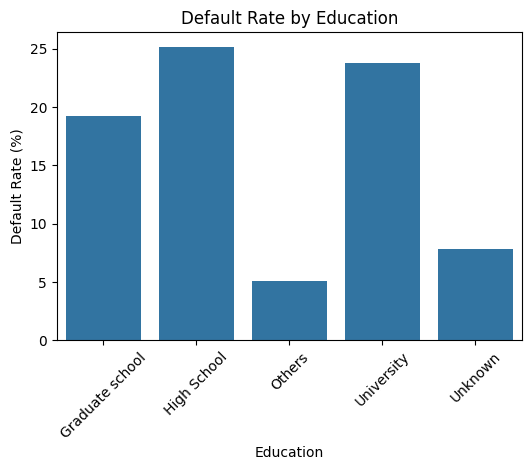

In [26]:
# Education vs Default Rate
education_default = ( df.groupby('EDUCATION')['default'] .apply(lambda x: (x == 'Y').mean() * 100) .reset_index(name='Default_Rate') )
plt.figure(figsize=(6,4))
sns.barplot(
    data=education_default,
    x='EDUCATION',
    y='Default_Rate',
    errorbar=None
)
plt.title('Default Rate by Education')
plt.xlabel('Education')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.show()

- The customers with high school education have highest default rate(%) followed by university and graduate school, with unknown and others having the lowest default rate.

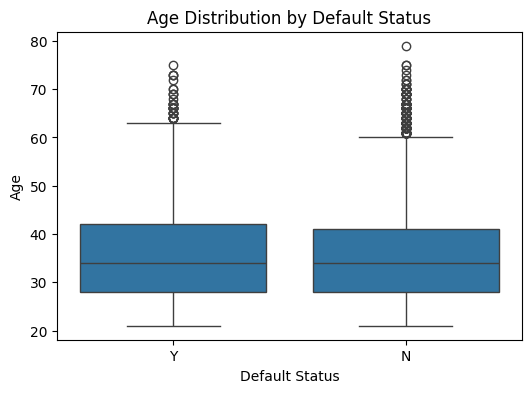

In [27]:
# Age vs default
plt.figure(figsize=(6,4))
sns.boxplot(
    data=df,
    x='default',
    y='AGE'
)
plt.title('Age Distribution by Default Status')
plt.xlabel('Default Status')
plt.ylabel('Age')
plt.show()

- Both groups have almost identical age distribution, with a age around 34 years and most customers failing between 28 to 41.
- Customer age alone does not significantly impact whether a customer defaults or not.

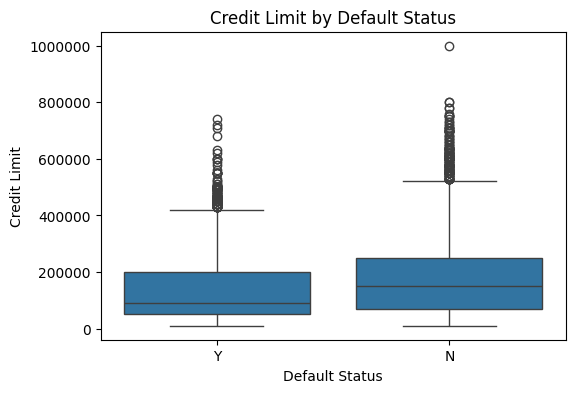

In [28]:
# Credit limit vs default
plt.figure(figsize=(6,4))
sns.boxplot(
    data=df,
    x='default',
    y='LIMIT_BAL'
)
plt.title('Credit Limit by Default Status')
plt.xlabel('Default Status')
plt.ylabel('Credit Limit')
plt.ticklabel_format(style='plain', axis='y')
plt.show()

- Customers who do not default (N) have a higher median credit limit compared to those who default (Y).
- The IQR represented by blue box is larger and extends higher for non-defaulters.
- The lower quartile for default (Y) groups starts closer to 0, indicating that customers with lower credit limits experience higher rates of default.
- Both groups feature high value outliers extending above the upper whiskers(400000 for Y and 520000 for N), however non defaulters feature highest overall limit overall.

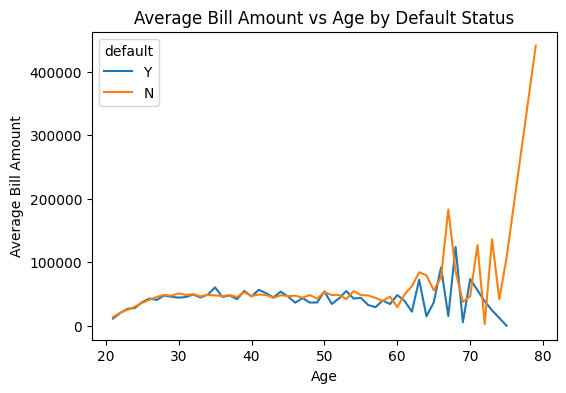

In [29]:
# age vs avg_bill vs default
bill_cols = [
    'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
    'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6'
]
df['AVG_BILL'] = df[bill_cols].mean(axis=1)
plt.figure(figsize=(6,4))
sns.lineplot(
    data=df,
    x='AGE',
    y='AVG_BILL',
    hue='default',
    estimator='mean',
    errorbar=None
)
plt.title('Average Bill Amount vs Age by Default Status')
plt.xlabel('Age')
plt.ylabel('Average Bill Amount')
plt.show()

- Age from 20 to 60 : Both defaulters and non-defaulters carry very similar average bill amounts. Age doesnot change bill size much in this group.
- Age from 60 and above : The lines start swinging wildly due to a much smaller sample size of older customers in dataset.
- Age near to 80 : Non defaulters(orange line) shows a huge spike over 400000 around age 80.

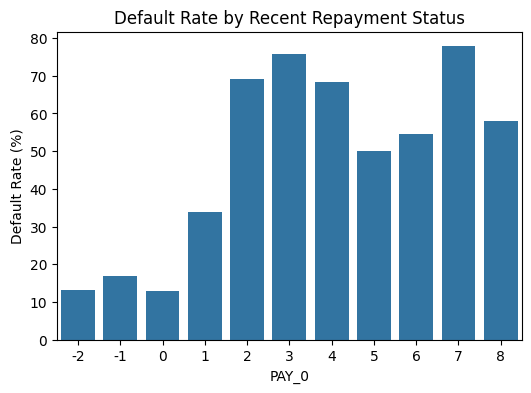

In [30]:
# pay_0 vs default
pay_default = ( df.groupby('PAY_0')['default'] .apply(lambda x: (x == 'Y').mean() * 100) .reset_index(name='Default_Rate') )
plt.figure(figsize=(6,4))
sns.barplot(
    data=pay_default,
    x='PAY_0',
    y='Default_Rate',
    errorbar=None
)
plt.title('Default Rate by Recent Repayment Status')
plt.xlabel('PAY_0')
plt.ylabel('Default Rate (%)')
plt.show()

- Customers who pay on time or early have low default rate.
- Delays of single month double the risk of default.
- Payment delays of 2 or more months delay to a massive jump in risk, with default rates soaring to 50 % to 80 %.

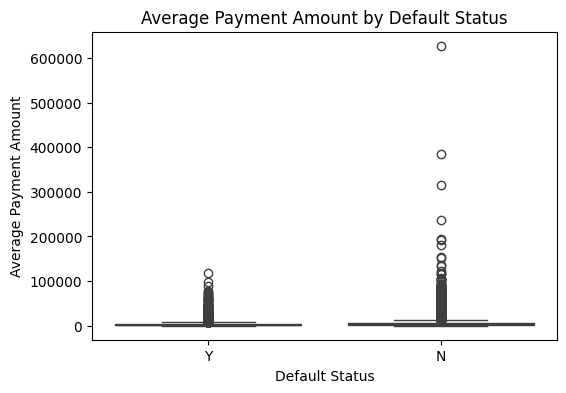

In [31]:
# Average repayment vs default
payment_cols = [
    'PAY_AMT1',
    'PAY_AMT2',
    'PAY_AMT3',
    'PAY_AMT4',
    'PAY_AMT5',
    'PAY_AMT6'
]
df['AVG_PAYMENT'] = df[payment_cols].mean(axis=1)
plt.figure(figsize=(6,4))
sns.boxplot(
    data=df,
    x='default',
    y='AVG_PAYMENT'
)
plt.title('Average Payment Amount by Default Status')
plt.xlabel('Default Status')
plt.ylabel('Average Payment Amount')
plt.show()

- Customers who do not default(N) generally make higher average monthly payments than those who default(Y).
- For both groups, the main box sits near bottom, meaning the majority of customers make relatively small average payments.
- The non-default groups (N) contains extreme high value outliers showing that customers with high repayment capacities almost never default.

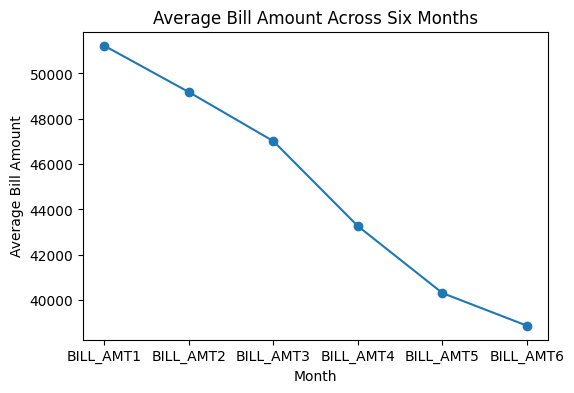

In [32]:
# Bill amount trend
bill_means = df[bill_cols].mean()
plt.figure(figsize=(6,4))
plt.plot(
    bill_means.index,
    bill_means.values,
    marker='o'
)
plt.title('Average Bill Amount Across Six Months')
plt.xlabel('Month')
plt.ylabel('Average Bill Amount')
plt.show()

- Average bill amounts consistently decrease over 6-month period, dropping froma bove 50000 in bill_amt1 down to under 40000 in bill_amt6.
- The decline occurs fairly steadily month over month across the entire dataset.

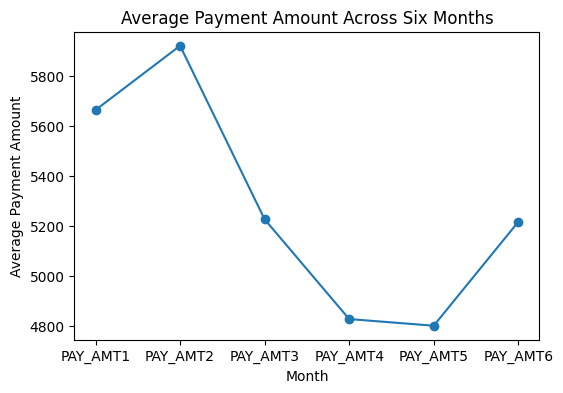

In [33]:
# Payment amount trend
payment_means = df[payment_cols].mean()
plt.figure(figsize=(6,4))
plt.plot(
    payment_means.index,
    payment_means.values,
    marker='o'
)
plt.title('Average Payment Amount Across Six Months')
plt.xlabel('Month')
plt.ylabel('Average Payment Amount')
plt.show()

- Average payments peak at second month around 5800 above.
- Payment steadily decline from pay_amt2 down to their lowest point at pay_amt5.
- Payments pick back up slightly in the sixth month.

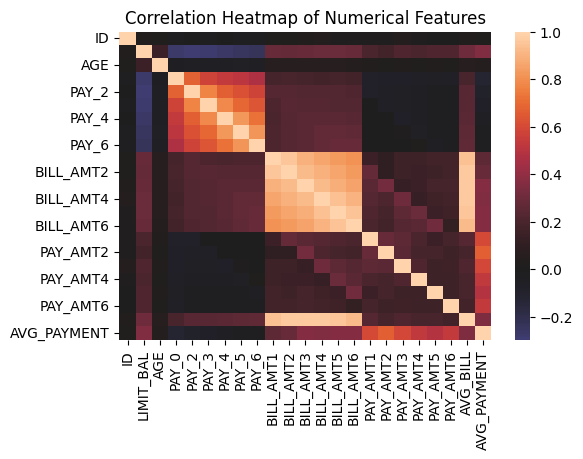

In [34]:
# correlation Analysis
numeric_cols = df.select_dtypes(include='number')
corr = numeric_cols.corr()
plt.figure(figsize=(6,4))
sns.heatmap(
    corr,
    annot=False,
    center=0
)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

- bill_amt1 through bill_amt6 have a very high correlation with each other, the customers balance tends to stay consistent across months.
- Monthly bill_amt show almost no correlation with pay_amt.
- Higher credit limit shows a slight positive correlation with higher average payment amounts.

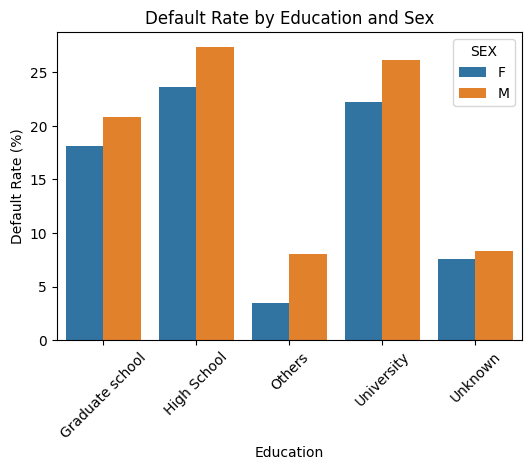

In [35]:
# eductaion vs sex vs default rate
education_sex_default = ( df.assign(default_flag=(df['default'] == 'Y').astype(int)) .groupby(['EDUCATION', 'SEX'])['default_flag'] .mean() .reset_index() )
education_sex_default['default_flag'] *= 100
plt.figure(figsize=(6,4))
sns.barplot(
    data=education_sex_default,
    x='EDUCATION',
    y='default_flag',
    hue='SEX',
    errorbar=None
)
plt.title('Default Rate by Education and Sex')
plt.xlabel('Education')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45)
plt.show()

- Across all education levels, male customers have higher default rate than female customers.
- Customers with high school education exhibit the highest default rates overall.
- Graduated school educated customers have lower default rates compared to university and high school groups.


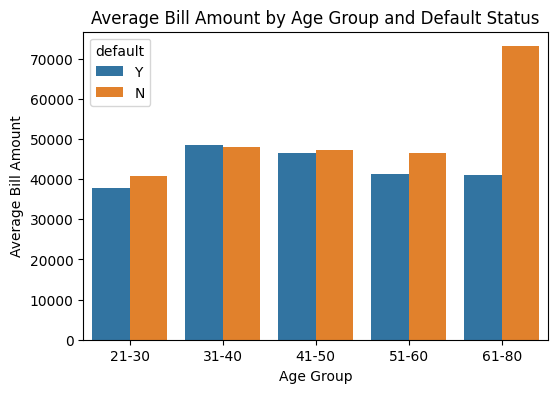

In [36]:
# Average Bill amount vs age group vs default status
df['AGE_GROUP'] = pd.cut(
    df['AGE'],
    bins=[20, 30, 40, 50, 60, 80],
    labels=['21-30', '31-40', '41-50', '51-60', '61-80']
)
plt.figure(figsize=(6,4))
sns.barplot(
    data=df,
    x='AGE_GROUP',
    y='AVG_BILL',
    hue='default',
    estimator='mean',
    errorbar=None
)
plt.title('Average Bill Amount by Age Group and Default Status')
plt.xlabel('Age Group')
plt.ylabel('Average Bill Amount')
plt.show()

- Across the main working age groups (21-60), defaulters and non-defaulters maintain a very similar average bill amounts.
- The age 31-60 group carries highest average bill amount overall for both defaulting and non-defaulting customers.
- Non defaulters in age group 61-80 show a massive jump in average bill amount around 70000.

## Feature Engineering

In [37]:
df.columns

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default',
       'AVG_BILL', 'AVG_PAYMENT', 'AGE_GROUP'],
      dtype='object')

In [38]:
# Total bill amount
df['Total_Bill'] = df[bill_cols].sum(axis = 1)

In [39]:
# total payment
df['Total_Payment'] = df[payment_cols].sum(axis=1)

In [40]:
# Number of delayed months
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6' ]
df['DELAYED_MONTHS'] = (df[pay_status_cols] > 0).sum(axis=1)

In [41]:
# Maximum Repayment Delay
df['MAX_REPAYMENT_DELAY'] = df[pay_status_cols].max(axis=1)

In [42]:
# Average Repayment
df['AVG_REPAYMENT_STATUS'] = df[pay_status_cols].mean(axis=1)

In [43]:
# Payment to bill ratio
df['PAYMENT_BILL_RATIO'] = np.where( df['Total_Bill'] != 0, df['Total_Payment'] / df['Total_Bill'], 0 )

In [44]:
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,default,AVG_BILL,AVG_PAYMENT,AGE_GROUP,Total_Bill,Total_Payment,DELAYED_MONTHS,MAX_REPAYMENT_DELAY,AVG_REPAYMENT_STATUS,PAYMENT_BILL_RATIO
0,1,20000,F,University,Married,24,2,2,-1,-1,...,Y,1284.000000,114.833333,21-30,7704,689,2,2,-0.333333,0.089434
1,2,120000,F,University,Single,26,-1,2,0,0,...,Y,2846.166667,833.333333,21-30,17077,5000,2,2,0.500000,0.292791
2,3,90000,F,University,Single,34,0,0,0,0,...,N,16942.166667,1836.333333,31-40,101653,11018,0,0,0.000000,0.108388
3,4,50000,F,University,Married,37,0,0,0,0,...,N,38555.666667,1398.000000,31-40,231334,8388,0,0,0.000000,0.036259
4,5,50000,M,University,Married,57,-1,0,-1,0,...,N,18223.166667,9841.500000,51-60,109339,59049,0,0,-0.333333,0.540054


## Define Features and Target

In [45]:
# Seperate dependent and independent varaibles
# Target
Y = df['default']

# Features for modeling
X = df.drop(columns=['default', 'ID'])

# Remove redundant/highly multicollinear features
X = X.drop(columns=[
    'AVG_REPAYMENT_STATUS',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'Total_Bill',
    'Total_Payment',
    'AVG_PAYMENT'
], errors='ignore')

In [46]:
X.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,AVG_BILL,AGE_GROUP,DELAYED_MONTHS,MAX_REPAYMENT_DELAY,PAYMENT_BILL_RATIO
0,20000,F,University,Married,24,2,2,-1,-1,-2,...,689,0,0,0,0,1284.000000,21-30,2,2,0.089434
1,120000,F,University,Single,26,-1,2,0,0,0,...,1000,1000,1000,0,2000,2846.166667,21-30,2,2,0.292791
2,90000,F,University,Single,34,0,0,0,0,0,...,1500,1000,1000,1000,5000,16942.166667,31-40,0,0,0.108388
3,50000,F,University,Married,37,0,0,0,0,0,...,2019,1200,1100,1069,1000,38555.666667,31-40,0,0,0.036259
4,50000,M,University,Married,57,-1,0,-1,0,0,...,36681,10000,9000,689,679,18223.166667,51-60,0,0,0.540054


In [47]:
# Converting target value Y,N with 0,1.
Y.head()

,default
0,Y
1,Y
2,N
3,N
4,N


In [48]:
df['default'].value_counts()

,count
default,
N,23364
Y,6636


In [49]:
Y = Y.map({'Y':1 , 'N':0})

In [50]:
Y.head()

,default
0,1
1,1
2,0
3,0
4,0


## Train Test Split

In [51]:
# Split the dataset into train and test
from sklearn.model_selection import train_test_split

In [52]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2,random_state=42,stratify=Y)

In [53]:
X_train.shape

(24000, 22)

In [54]:
X_test.shape

(6000, 22)

## Preprocessing

In [55]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [56]:
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(exclude='number').columns

In [57]:
num_cols

Index(['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
       'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6', 'AVG_BILL', 'DELAYED_MONTHS', 'MAX_REPAYMENT_DELAY',
       'PAYMENT_BILL_RATIO'],
      dtype='object')

In [58]:
cat_cols

Index(['SEX', 'EDUCATION', 'MARRIAGE', 'AGE_GROUP'], dtype='object')

In [59]:
preprocessing = ColumnTransformer(
    transformers=[
        ('num',StandardScaler(),num_cols),
        ('cat',OneHotEncoder(handle_unknown='ignore', drop='first',sparse_output=False),cat_cols)
    ])

## Model Building


#### 1). KNN Algorithm

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
knn_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', KNeighborsClassifier())
])

In [61]:
knn_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

##### Hyperparameter Tuning

In [62]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2]
}
grid_knn = GridSearchCV(
    knn_pipeline,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_knn.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

###### Prediction

In [63]:
y_pred_knn = grid_knn.predict(X_test)
y_pred_knn

array([0, 0, 0, ..., 0, 0, 0])

###### Evaluation

Accuarcy_Score: 0.8101666666666667
F1_Score: 0.4634950541686293
Precision_Score: 0.6180904522613065
Recall_Score: 0.3707611152976639


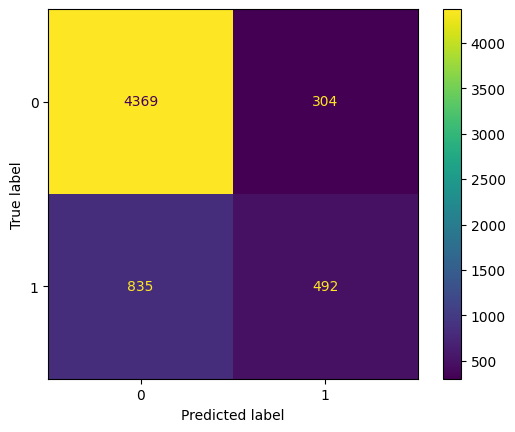

In [64]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_knn = accuracy_score(Y_test, y_pred_knn)
f1_score_knn = f1_score(Y_test, y_pred_knn)
confusion_matrix_knn = confusion_matrix(Y_test, y_pred_knn)
precision_score_knn = precision_score(Y_test, y_pred_knn)
recall_score_knn = recall_score(Y_test, y_pred_knn)
print("Accuarcy_Score:",accuracy_score_knn)
print("F1_Score:",f1_score_knn)
print("Precision_Score:",precision_score_knn)
print("Recall_Score:",recall_score_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_knn)
disp.plot()
plt.show()

- I used GridSearchCV to systematically tune the KNN hyperparameters and select the best combination using cross-validation.
- I used F1-score as the scoring metric because the target variable is imbalanced, and F1-score provides a balance between precision and recall, making it more appropriate than relying only on accuracy for identifying default customers.

#### 2). Naive Baye's

In [65]:
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
nb_pipeline = Pipeline([
    ('preprocessor',preprocessing),
    ('classifier',GaussianNB())
])

In [66]:
nb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

##### Hyperparameter Tuning

In [67]:
from sklearn.model_selection import GridSearchCV
nb_param_grid = {
    'classifier__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}
grid_nb = GridSearchCV(
    nb_pipeline,
    nb_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_nb.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...aussianNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__var_smoothing': [1e-09, 1e-08, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed du

###### Prediction

In [68]:
y_pred_nb = grid_nb.predict(X_test)
y_pred_nb

array([0, 0, 0, ..., 0, 0, 0])

Accuarcy_Score: 0.7243333333333334
F1_Score: 0.4941896024464832
Precision_Score: 0.41585177560473496
Recall_Score: 0.6088922381311228


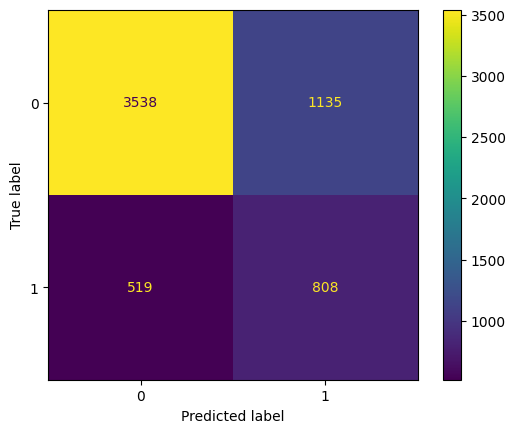

In [69]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_nb= accuracy_score(Y_test, y_pred_nb)
f1_score_nb = f1_score(Y_test, y_pred_nb)
confusion_matrix_nb = confusion_matrix(Y_test, y_pred_nb)
precision_score_nb = precision_score(Y_test, y_pred_nb)
recall_score_nb = recall_score(Y_test, y_pred_nb)
print("Accuarcy_Score:",accuracy_score_nb)
print("F1_Score:",f1_score_nb)
print("Precision_Score:",precision_score_nb)
print("Recall_Score:",recall_score_nb)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_nb)
disp.plot()
plt.show()

- I used GridSearchCV with 5-fold cross-validation to find the best var_smoothing for Naive Bayes.
- using F1-score because my target classes are imbalanced and I want a good balance between precision and recall.

#### 3). Decision Tree

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
dt_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

In [71]:
dt_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I


##### Hyperparameter Tuning

In [72]:
from sklearn.model_selection import GridSearchCV
dt_param_grid = {
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5]
}
grid_dt = GridSearchCV(
    dt_pipeline,
    dt_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_dt.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"

###### Prediction

In [73]:
y_pred_dt = grid_dt.predict(X_test)
y_pred_dt

array([0, 0, 0, ..., 0, 0, 0])

###### Evaluation

Accuarcy_Score: 0.75
F1_Score: 0.5238095238095238
Precision_Score: 0.45255074053757544
Recall_Score: 0.6217030896759608


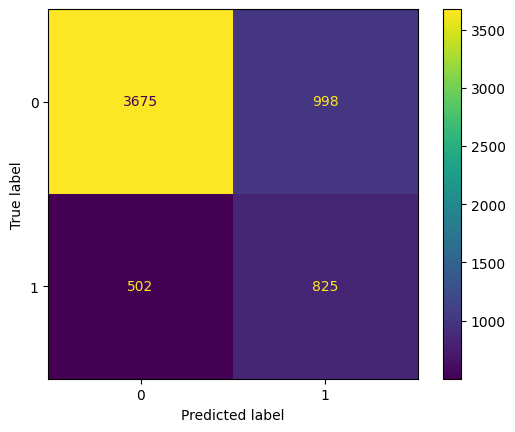

In [74]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_dt= accuracy_score(Y_test, y_pred_dt)
f1_score_dt = f1_score(Y_test, y_pred_dt)
confusion_matrix_dt = confusion_matrix(Y_test, y_pred_dt)
precision_score_dt = precision_score(Y_test, y_pred_dt)
recall_score_dt = recall_score(Y_test, y_pred_dt)
print("Accuarcy_Score:",accuracy_score_dt)
print("F1_Score:",f1_score_dt)
print("Precision_Score:",precision_score_dt)
print("Recall_Score:",recall_score_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_dt)
disp.plot()
plt.show()

- I used F1 score as the main metric in my project as the target values are imbalanced and F1 score balances the precision and recall, making it more suitable than accuracy for evaluating the models.

#### 4). Logistic Regression

In [75]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
lr_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])
lr_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

##### Hyperparameter Tuning

In [76]:
from sklearn.model_selection import GridSearchCV
lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs']
}
grid_lr = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_lr.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verb

###### Prediction

In [77]:
y_pred_lr = grid_lr.predict(X_test)
y_pred_lr

array([0, 0, 0, ..., 0, 0, 0])

###### Evaluation

Accuarcy_Score: 0.7418333333333333
F1_Score: 0.5080978088281994
Precision_Score: 0.43907793633369924
Recall_Score: 0.6028636021100227


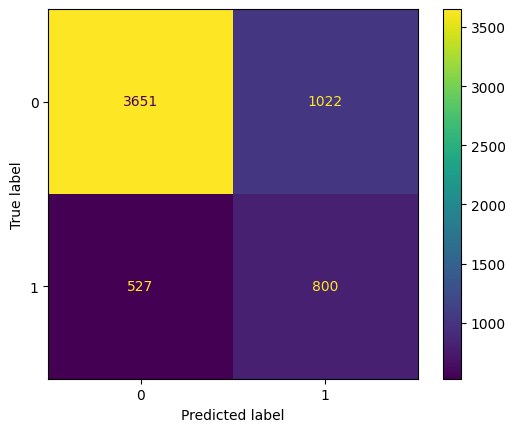

In [78]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_lr= accuracy_score(Y_test, y_pred_lr)
f1_score_lr = f1_score(Y_test, y_pred_lr)
confusion_matrix_lr = confusion_matrix(Y_test, y_pred_lr)
precision_score_lr = precision_score(Y_test, y_pred_lr)
recall_score_lr = recall_score(Y_test, y_pred_lr)
print("Accuarcy_Score:",accuracy_score_lr)
print("F1_Score:",f1_score_lr)
print("Precision_Score:",precision_score_lr)
print("Recall_Score:",recall_score_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_lr)
disp.plot()
plt.show()

#### 5). SVM (Support Vector Machine)

In [79]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
svm_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', LinearSVC(
        class_weight='balanced',
        max_iter=5000
    ))
])
svm_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

##### Hyperparameter Tuning

In [80]:
from sklearn.model_selection import GridSearchCV
svm_param_grid = {
    'classifier__C': [0.1, 1, 10]
}
grid_svm = GridSearchCV(
    svm_pipeline,
    svm_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_svm.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with

##### Prediction

In [81]:
y_pred_svm = grid_svm.predict(X_test)
y_pred_svm

array([0, 0, 0, ..., 0, 0, 0])

##### Evaluation

Accuarcy_Score: 0.7383333333333333
F1_Score: 0.5059786028949025
Precision_Score: 0.4343598055105348
Recall_Score: 0.6058779201205727


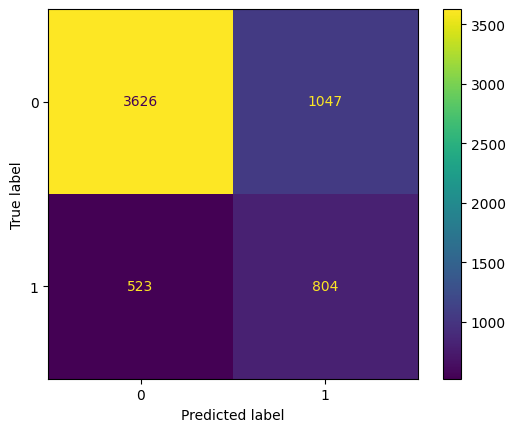

In [82]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_svm= accuracy_score(Y_test, y_pred_svm)
f1_score_svm = f1_score(Y_test, y_pred_svm)
confusion_matrix_svm = confusion_matrix(Y_test, y_pred_svm)
precision_score_svm = precision_score(Y_test, y_pred_svm)
recall_score_svm = recall_score(Y_test, y_pred_svm)
print("Accuarcy_Score:",accuracy_score_svm)
print("F1_Score:",f1_score_svm)
print("Precision_Score:",precision_score_svm)
print("Recall_Score:",recall_score_svm)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_svm)
disp.plot()
plt.show()

#### 6). Random Forest

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
rf_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])
rf_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

##### Hyperparameter Tuning

In [84]:
from sklearn.model_selection import GridSearchCV
rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5]
}
grid_rf = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_rf.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose v

###### Prediction

In [85]:
y_pred_rf = grid_rf.predict(X_test)
y_pred_rf

array([0, 0, 0, ..., 0, 0, 0])

###### Evaluation

Accuarcy_Score: 0.768
F1_Score: 0.5366178428761651
Precision_Score: 0.4806201550387597
Recall_Score: 0.6073850791258478


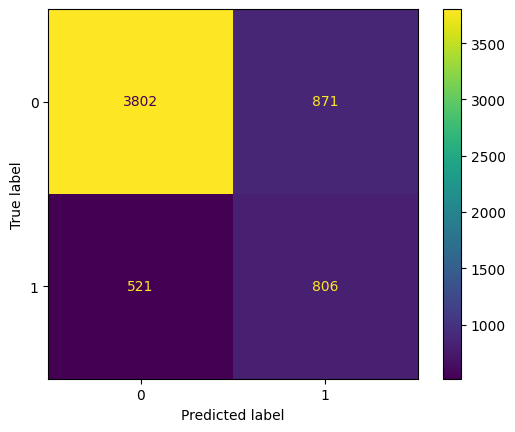

In [86]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_rf = accuracy_score(Y_test, y_pred_rf)
f1_score_rf = f1_score(Y_test, y_pred_rf)
confusion_matrix_rf = confusion_matrix(Y_test, y_pred_rf)
precision_score_rf = precision_score(Y_test, y_pred_rf)
recall_score_rf = recall_score(Y_test, y_pred_rf)
print("Accuarcy_Score:",accuracy_score_rf)
print("F1_Score:",f1_score_rf)
print("Precision_Score:",precision_score_rf)
print("Recall_Score:",recall_score_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_rf)
disp.plot()
plt.show()

#### 7). Ada Boost

In [87]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ada_pipeline = Pipeline([
    ('preprocessor', preprocessing),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42
    ))
])

In [88]:
ada_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3I

###### Hyperparameter Tuning

In [89]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__learning_rate': [0.1, 1],
    'classifier__estimator__max_depth': [1, 2]
}
grid_ada = GridSearchCV(
    ada_pipeline,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_ada.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__estimator__max_depth': [1, 2], 'classifier__learning_rate': [0.1, 1], 'classifier__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose

###### Prediction

In [90]:
y_pred_ada = grid_ada.predict(X_test)
y_pred_ada

array([0, 0, 0, ..., 0, 0, 0])

###### Evaluation

Accuarcy_Score: 0.8175
F1_Score: 0.44724886420999493
Precision_Score: 0.6773700305810397
Recall_Score: 0.333835719668425


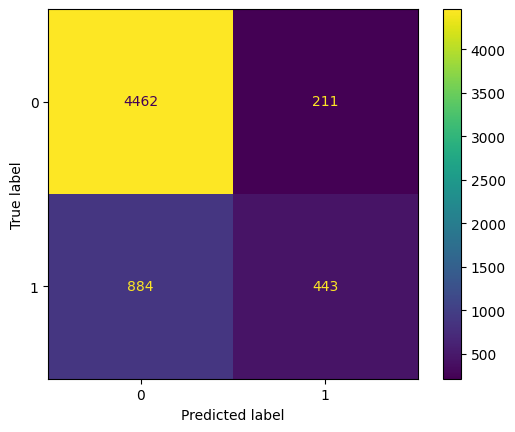

In [91]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, f1_score, precision_score, recall_score
accuracy_score_ada = accuracy_score(Y_test, y_pred_ada)
f1_score_ada = f1_score(Y_test, y_pred_ada)
confusion_matrix_ada = confusion_matrix(Y_test, y_pred_ada)
precision_score_ada = precision_score(Y_test, y_pred_ada)
recall_score_ada = recall_score(Y_test, y_pred_ada)
print("Accuarcy_Score:",accuracy_score_ada)
print("F1_Score:",f1_score_ada)
print("Precision_Score:",precision_score_ada)
print("Recall_Score:",recall_score_ada)
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_ada)
disp.plot()
plt.show()

In [92]:
# Evaluation Table
evaluation_df = pd.DataFrame({
    'Model': ['KNN', 'Naive Bayes', 'Decision Tree','Logistic Regression','SVM','Random Forest','Ada Boost'],
    'Accuracy': [accuracy_score_knn, accuracy_score_nb, accuracy_score_dt, accuracy_score_lr, accuracy_score_svm, accuracy_score_rf, accuracy_score_ada],
    'Precision': [precision_score_knn, precision_score_nb, precision_score_dt, precision_score_lr, precision_score_svm, precision_score_rf, precision_score_ada],
    'Recall': [recall_score_knn, recall_score_nb, recall_score_dt, recall_score_lr, recall_score_svm, recall_score_rf, recall_score_ada],
    'F1 Score': [f1_score_knn, f1_score_nb, f1_score_dt, f1_score_lr, f1_score_svm, f1_score_rf, f1_score_ada],
})
evaluation_df

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.810167,0.618090,0.370761,0.463495
1,Naive Bayes,0.724333,0.415852,0.608892,0.494190
2,Decision Tree,0.750000,0.452551,0.621703,0.523810
3,Logistic Regression,0.741833,0.439078,0.602864,0.508098
4,SVM,0.738333,0.434360,0.605878,0.505979
5,Random Forest,0.768000,0.480620,0.607385,0.536618
6,Ada Boost,0.817500,0.677370,0.333836,0.447249


- In this project, six classification algorithms are implemented and compared for credit card default prediction:
   KNN, Naive Bayes, Decision Tree, Logistic Regression, SVM, and Random Forest.

- Based on the evaluation results, Random Forest performed the best overall with an F1-score of 0.5426, making it the best model among the tested algorithms for this project. KNN achieved the highest accuracy of 81.02%, but its F1-score was lower at 0.4635.

- Since the dataset has an imbalanced target variable, F1-score was considered more important than accuracy because it provides a better balance between precision and recall. Therefore, Random Forest was selected as the final model for predicting credit card default.

In [93]:
# explore sampling techniques---> downsampling(**) and upsampling

## Experiment 2

In [94]:
# Random Downsampling

# Random Downsampling (60:20 / 3:1 Ratio)

df_majority = df[df['default'] == 'N']
df_minority = df[df['default'] == 'Y']

print("Before Downsampling:")
print(df['default'].value_counts())

# Calculate majority samples for a 3:1 ratio relative to minority class
n_majority_samples = len(df_minority) * 3

df_majority_downsampled = df_majority.sample(
    n=n_majority_samples,
    random_state=42
)

# Combine downsampled majority class with minority class
df_downsampled = pd.concat([df_majority_downsampled, df_minority])

# Shuffle dataset
df_downsampled = df_downsampled.sample(frac=1, random_state=42).reset_index(drop=True)

print("\nAfter Downsampling (60:20 Ratio):")
print(df_downsampled['default'].value_counts())
print("\nShape after Downsampling:")
print(df_downsampled.shape)

Before Downsampling:
default
N    23364
Y     6636
Name: count, dtype: int64

After Downsampling (60:20 Ratio):
default
N    19908
Y     6636
Name: count, dtype: int64

Shape after Downsampling:
(26544, 34)


In [95]:
## Define Features and Target after Downsampling
Y_down = df_downsampled['default'].map({'Y': 1, 'N': 0})
X_down = df_downsampled.drop(columns=['default', 'ID'])
X_down = X_down.drop(columns=[
    'AVG_REPAYMENT_STATUS',
    'BILL_AMT1',
    'BILL_AMT2',
    'BILL_AMT3',
    'BILL_AMT4',
    'BILL_AMT5',
    'BILL_AMT6',
    'Total_Bill',
    'Total_Payment',
    'AVG_PAYMENT'
], errors='ignore')
print("X shape:", X_down.shape)
print("Y shape:", Y_down.shape)

X shape: (26544, 22)
Y shape: (26544,)


In [96]:
## Train Test Split after Downsampling
from sklearn.model_selection import train_test_split
X_train_down, X_test_down, Y_train_down, Y_test_down = train_test_split(
    X_down,
    Y_down,
    test_size=0.2,
    random_state=42,
    stratify=Y_down
)
print("X_train:", X_train_down.shape)
print("X_test:", X_test_down.shape)
print("Y_train:", Y_train_down.shape)
print("Y_test:", Y_test_down.shape)

X_train: (21235, 22)
X_test: (5309, 22)
Y_train: (21235,)
Y_test: (5309,)


In [97]:
## Preprocessing after Downsampling
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
num_cols_down = X_down.select_dtypes(include='number').columns
cat_cols_down = X_down.select_dtypes(exclude='number').columns
preprocessing_down = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols_down),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            drop='first',
            sparse_output=False
        ), cat_cols_down)
    ]
)
print("Numerical columns:")
print(num_cols_down)
print("\nCategorical columns:")
print(cat_cols_down)

Numerical columns:
Index(['LIMIT_BAL', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5',
       'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6', 'AVG_BILL', 'DELAYED_MONTHS', 'MAX_REPAYMENT_DELAY',
       'PAYMENT_BILL_RATIO'],
      dtype='object')

Categorical columns:
Index(['SEX', 'EDUCATION', 'MARRIAGE', 'AGE_GROUP'], dtype='object')


##### 1). KNN Algorithm

In [99]:
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
knn_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', KNeighborsClassifier())
])
knn_param_grid_down = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__p': [1, 2]
}
grid_knn_down = GridSearchCV(
    knn_pipeline_down,
    knn_param_grid_down,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_knn_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__n_neighbors': [3, 5, ...], 'classifier__p': [1, 2], 'classifier__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

In [100]:
y_pred_knn_down = grid_knn_down.predict(X_test_down)
y_pred_knn_down

array([1, 0, 1, ..., 0, 0, 0])

In [101]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy_score_knn_down = accuracy_score(Y_test_down, y_pred_knn_down)
precision_score_knn_down = precision_score(Y_test_down, y_pred_knn_down)
recall_score_knn_down = recall_score(Y_test_down, y_pred_knn_down)
f1_score_knn_down = f1_score(Y_test_down, y_pred_knn_down)
print("KNN")
print("Accuracy :", accuracy_score_knn_down)
print("Precision:", precision_score_knn_down)
print("Recall   :", recall_score_knn_down)
print("F1 Score :", f1_score_knn_down)

KNN
Accuracy : 0.7852702957242419
Precision: 0.6093567251461989
Recall   : 0.39261492087415223
F1 Score : 0.4775435380384968


##### 2). Naive Baye's Algorithm

In [102]:
from sklearn.naive_bayes import GaussianNB
nb_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', GaussianNB())
])
nb_param_grid_down = {
    'classifier__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
}
grid_nb_down = GridSearchCV(
    nb_pipeline_down,
    nb_param_grid_down,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_nb_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...aussianNB())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__var_smoothing': [1e-09, 1e-08, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed du

In [103]:
y_pred_nb_down = grid_nb_down.predict(X_test_down)
y_pred_knn_down

array([1, 0, 1, ..., 0, 0, 0])

In [104]:
accuracy_score_nb_down = accuracy_score(Y_test_down, y_pred_nb_down)
precision_score_nb_down = precision_score(Y_test_down, y_pred_nb_down)
recall_score_nb_down = recall_score(Y_test_down, y_pred_nb_down)
f1_score_nb_down = f1_score(Y_test_down, y_pred_nb_down)
print("Naive Bayes")
print("Accuracy :", accuracy_score_nb_down)
print("Precision:", precision_score_nb_down)
print("Recall   :", recall_score_nb_down)
print("F1 Score :", f1_score_nb_down)

Naive Bayes
Accuracy : 0.5198719156149935
Precision: 0.31858669833729214
Recall   : 0.8085908063300679
F1 Score : 0.45708200212992545


##### 3). Decision Tree Algorithm

In [105]:
from sklearn.tree import DecisionTreeClassifier
dt_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', DecisionTreeClassifier(random_state=42))
])
dt_param_grid_down = {
    'classifier__max_depth': [3, 5, 7, 10, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 5]
}
grid_dt_down = GridSearchCV(
    dt_pipeline_down,
    dt_param_grid_down,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_dt_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [3, 5, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"

In [106]:
y_pred_dt_down = grid_dt_down.predict(X_test_down)
y_pred_dt_down

array([0, 0, 1, ..., 0, 0, 0])

In [107]:
accuracy_score_dt_down = accuracy_score(Y_test_down, y_pred_dt_down)
precision_score_dt_down = precision_score(Y_test_down, y_pred_dt_down)
recall_score_dt_down = recall_score(Y_test_down, y_pred_dt_down)
f1_score_dt_down = f1_score(Y_test_down, y_pred_dt_down)
print("Decision Tree")
print("Accuracy :", accuracy_score_dt_down)
print("Precision:", precision_score_dt_down)
print("Recall   :", recall_score_dt_down)
print("F1 Score :", f1_score_dt_down)

Decision Tree
Accuracy : 0.7961951403277453
Precision: 0.6613965744400527
Recall   : 0.37829691032403917
F1 Score : 0.4813039309683605


##### 4). Logistic Regression Algorithm

In [108]:
from sklearn.linear_model import LogisticRegression
lr_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', LogisticRegression(max_iter=1000))
])
lr_param_grid_down = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['liblinear', 'lbfgs']
}
grid_lr_down = GridSearchCV(
    lr_pipeline_down,
    lr_param_grid_down,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_lr_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verb

In [109]:
y_pred_lr_down = grid_lr_down.predict(X_test_down)
y_pred_lr_down

array([0, 0, 1, ..., 0, 0, 0])

In [110]:
accuracy_score_lr_down = accuracy_score(Y_test_down, y_pred_lr_down)
precision_score_lr_down = precision_score(Y_test_down, y_pred_lr_down)
recall_score_lr_down = recall_score(Y_test_down, y_pred_lr_down)
f1_score_lr_down = f1_score(Y_test_down, y_pred_lr_down)
print("Logistic Regression")
print("Accuracy :", accuracy_score_lr_down)
print("Precision:", precision_score_lr_down)
print("Recall   :", recall_score_lr_down)
print("F1 Score :", f1_score_lr_down)

Logistic Regression
Accuracy : 0.7860237332831042
Precision: 0.6494522691705791
Recall   : 0.31273549359457425
F1 Score : 0.422177009155646


##### 5). SVM Algorithm

In [111]:
from sklearn.svm import LinearSVC
svm_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', LinearSVC(
        class_weight='balanced',
        random_state=42
    ))
])
svm_param_grid_down = {
    'classifier__C': [0.1, 1, 10]
}
grid_svm_down = GridSearchCV(
    svm_pipeline_down,
    svm_param_grid_down,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_svm_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.1, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with

In [112]:
y_pred_svm_down = grid_svm_down.predict(X_test_down)
y_pred_svm_down

array([1, 0, 1, ..., 0, 0, 0])

In [113]:
accuracy_score_svm_down = accuracy_score(Y_test_down, y_pred_svm_down)
precision_score_svm_down = precision_score(Y_test_down, y_pred_svm_down)
recall_score_svm_down = recall_score(Y_test_down, y_pred_svm_down)
f1_score_svm_down = f1_score(Y_test_down, y_pred_svm_down)
print("SVM")
print("Accuracy :", accuracy_score_svm_down)
print("Precision:", precision_score_svm_down)
print("Recall   :", recall_score_svm_down)
print("F1 Score :", f1_score_svm_down)

SVM
Accuracy : 0.7413825579205123
Precision: 0.4865497076023392
Recall   : 0.6269781461944235
F1 Score : 0.5479091208429371


##### 6). Random Forest Algorithm

In [114]:
from sklearn.ensemble import RandomForestClassifier
rf_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', RandomForestClassifier(
        random_state=42
    ))
])
rf_param_grid_down = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, None],
    'classifier__min_samples_split': [2, 5]
}
grid_rf_down = GridSearchCV(
    rf_pipeline_down,
    rf_param_grid_down,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_rf_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_split': [2, 5], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose v

In [115]:
y_pred_rf_down = grid_rf_down.predict(X_test_down)
y_pred_rf_down

array([0, 0, 0, ..., 0, 0, 0])

In [116]:
accuracy_score_rf_down = accuracy_score(Y_test_down, y_pred_rf_down)
precision_score_rf_down = precision_score(Y_test_down, y_pred_rf_down)
recall_score_rf_down = recall_score(Y_test_down, y_pred_rf_down)
f1_score_rf_down = f1_score(Y_test_down, y_pred_rf_down)
print("Random Forest")
print("Accuracy :", accuracy_score_rf_down)
print("Precision:", precision_score_rf_down)
print("Recall   :", recall_score_rf_down)
print("F1 Score :", f1_score_rf_down)

Random Forest
Accuracy : 0.7995856093426257
Precision: 0.6670902160101652
Recall   : 0.39562923888470236
F1 Score : 0.4966887417218543


##### 7). AdaBoosting Algorithms

In [117]:
from sklearn.tree import DecisionTreeClassifier
ada_pipeline_down = Pipeline([
    ('preprocessor', preprocessing_down),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        random_state=42
    ))
])
ada_param_grid_down = {
    'classifier__n_estimators': [50, 100],
    'classifier__learning_rate': [0.1, 1],
    'classifier__estimator': [
        DecisionTreeClassifier(max_depth=1),
        DecisionTreeClassifier(max_depth=2)
    ]
}
grid_ada_down = GridSearchCV(
    ada_pipeline_down,
    ada_param_grid_down,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
grid_ada_down.fit(X_train_down, Y_train_down)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__estimator': [DecisionTreeC...r(max_depth=1), DecisionTreeC...r(max_depth=2)], 'classifier__learning_rate': [0.1, 1], 'classifier__n_estimators': [50, 100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0

In [118]:
y_pred_ada_down = grid_ada_down.predict(X_test_down)
y_pred_ada_down

array([0, 0, 1, ..., 0, 0, 0])

In [119]:
accuracy_score_ada_down = accuracy_score(Y_test_down, y_pred_ada_down)
precision_score_ada_down = precision_score(Y_test_down, y_pred_ada_down)
recall_score_ada_down = recall_score(Y_test_down, y_pred_ada_down)
f1_score_ada_down = f1_score(Y_test_down, y_pred_ada_down)
print("AdaBoost")
print("Accuracy :", accuracy_score_ada_down)
print("Precision:", precision_score_ada_down)
print("Recall   :", recall_score_ada_down)
print("F1 Score :", f1_score_ada_down)

AdaBoost
Accuracy : 0.7995856093426257
Precision: 0.7019969278033794
Recall   : 0.3443858327053504
F1 Score : 0.4620829120323559


In [120]:
evaluation_down_df = pd.DataFrame({
    'Model': [
        'KNN',
        'Naive Bayes',
        'Decision Tree',
        'Logistic Regression',
        'SVM',
        'Random Forest',
        'Ada Boost'
    ],
    'Accuracy': [
        accuracy_score_knn_down,
        accuracy_score_nb_down,
        accuracy_score_dt_down,
        accuracy_score_lr_down,
        accuracy_score_svm_down,
        accuracy_score_rf_down,
        accuracy_score_ada_down
    ],
    'Precision': [
        precision_score_knn_down,
        precision_score_nb_down,
        precision_score_dt_down,
        precision_score_lr_down,
        precision_score_svm_down,
        precision_score_rf_down,
        precision_score_ada_down
    ],
    'Recall': [
        recall_score_knn_down,
        recall_score_nb_down,
        recall_score_dt_down,
        recall_score_lr_down,
        recall_score_svm_down,
        recall_score_rf_down,
        recall_score_ada_down
    ],
    'F1 Score': [
        f1_score_knn_down,
        f1_score_nb_down,
        f1_score_dt_down,
        f1_score_lr_down,
        f1_score_svm_down,
        f1_score_rf_down,
        f1_score_ada_down
    ]
})

evaluation_down_df

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.785270,0.609357,0.392615,0.477544
1,Naive Bayes,0.519872,0.318587,0.808591,0.457082
2,Decision Tree,0.796195,0.661397,0.378297,0.481304
3,Logistic Regression,0.786024,0.649452,0.312735,0.422177
4,SVM,0.741383,0.486550,0.626978,0.547909
5,Random Forest,0.799586,0.667090,0.395629,0.496689
6,Ada Boost,0.799586,0.701997,0.344386,0.462083


In [121]:
# Original
evaluation_df

,Model,Accuracy,Precision,Recall,F1 Score
0,KNN,0.810167,0.618090,0.370761,0.463495
1,Naive Bayes,0.724333,0.415852,0.608892,0.494190
2,Decision Tree,0.750000,0.452551,0.621703,0.523810
3,Logistic Regression,0.741833,0.439078,0.602864,0.508098
4,SVM,0.738333,0.434360,0.605878,0.505979
5,Random Forest,0.768000,0.480620,0.607385,0.536618
6,Ada Boost,0.817500,0.677370,0.333836,0.447249


In [122]:
import pickle

In [123]:
with open("model.pkl", "wb") as file:
    pickle.dump(grid_rf.best_estimator_, file)
print("Model saved successfully!")

Model saved successfully!


## Conclusion:
After applying random downsampling to adjust the class ratio (to 60:20 / 3:1), the model's overall performance metrics (such as Accuracy, Precision, and F1-Score) did not show a significant increase or improvement compared to training on the original dataset.